**Лабораторная работа #3 часть 1**

**Применение логистической регрессии для решения задачи бинарной классификации**

Лабораторная работа выполняется на учебном наборе данных Iris, который поставляется в составе Scikit-Learn. Датасет описывает 3 сорта цветков ириса: `setosa`, `versicolor` и `virginica` путем измерения их лепестков. В датасете содержатся 4 параметра - `sepal length (cm)`, `sepal width (cm)`, `petal length (cm)`, `petal width (cm)` и целевая переменная, определяющая сорт. По каждому сорту содержится 50 записей, всего - 150 строк с данными.

Загрузка датасета:  
from sklearn.datasets import load_iris  
iris = load_iris()

**Описание задания к работе.**

Немного поисследуем датасет:

1. Используя `Matplotlib` отрисовать в цвете для всех 3 сортов зависимости: `sepal length - sepal width` и `petal length - petal width`
2. Использовать библиотеку `seaborn` и метод `pairplot` вывести результат либо для всего датасета либо для обучающей выборки.
3. Подготовим из имеющегося набора данных 2 датасета: в первом оставить `setosa` и `versicolor`, во втором - `versicolor` и `virginica`

Переходим к машинному обучению:

4. Каждый датасет разбить на обучающую и тестовые выборки
5. Использовать для обучения модель `LogisticRegression` с параметрами по умолчанию, например: `clf = LogisticRegression(random_state=0)`
6. Обучить модель (`fit`)
7. Сделать предсказание (`predict`)
8. Вывести значение точности модели (`score`)

Разделы 4 - 8 проделать для 2 датасетов полученных в п. 3.

9. Сгенерировать датасет случайным образом и провести для него бинарную классификацию. Выборку для классификации сгенерировать с помощью `make_classification` из библиотеки `scikit-learn`:  
`X, y = make_classification(n_samples=1000, n_features=2, n_redundant=0, n_informative=2, random_state=1, n_clusters_per_class=1)`  
Отрисовать полученный датасет используя `Matplotlib` и провести бинарную классификацию по пунктам 5 - 8

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris, make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [6]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [7]:
print(iris.target_names)

['setosa' 'versicolor' 'virginica']


### П.1

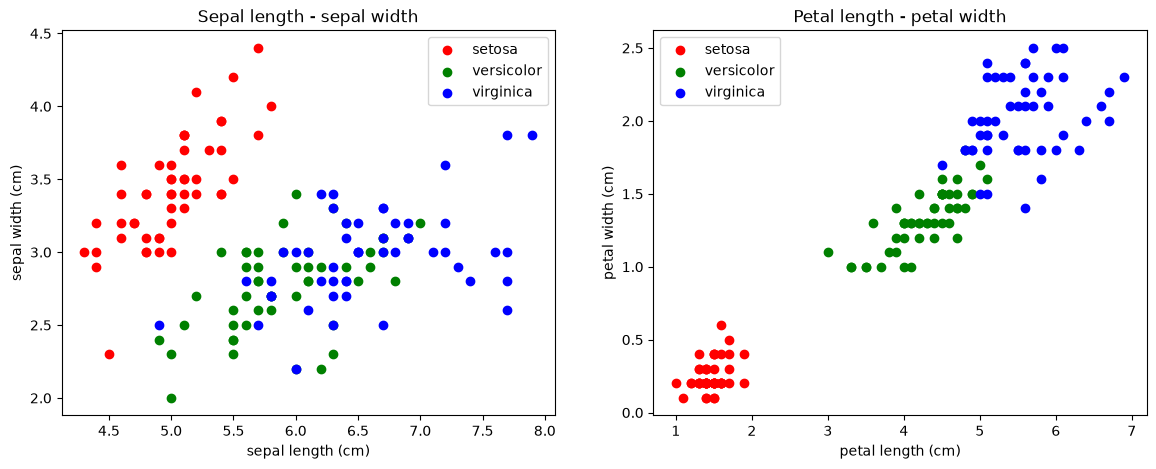

In [8]:
colors = ['red', 'green', 'blue']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, name in enumerate(iris.target_names):
    part = df[df['target'] == i]
    axes[0].scatter(part['sepal length (cm)'], part['sepal width (cm)'], color=colors[i], label=name)
    axes[1].scatter(part['petal length (cm)'], part['petal width (cm)'], color=colors[i], label=name)

axes[0].set_xlabel('sepal length (cm)')
axes[0].set_ylabel('sepal width (cm)')
axes[0].set_title('Sepal length - sepal width')
axes[0].legend()

axes[1].set_xlabel('petal length (cm)')
axes[1].set_ylabel('petal width (cm)')
axes[1].set_title('Petal length - petal width')
axes[1].legend()

plt.show()

### П.2

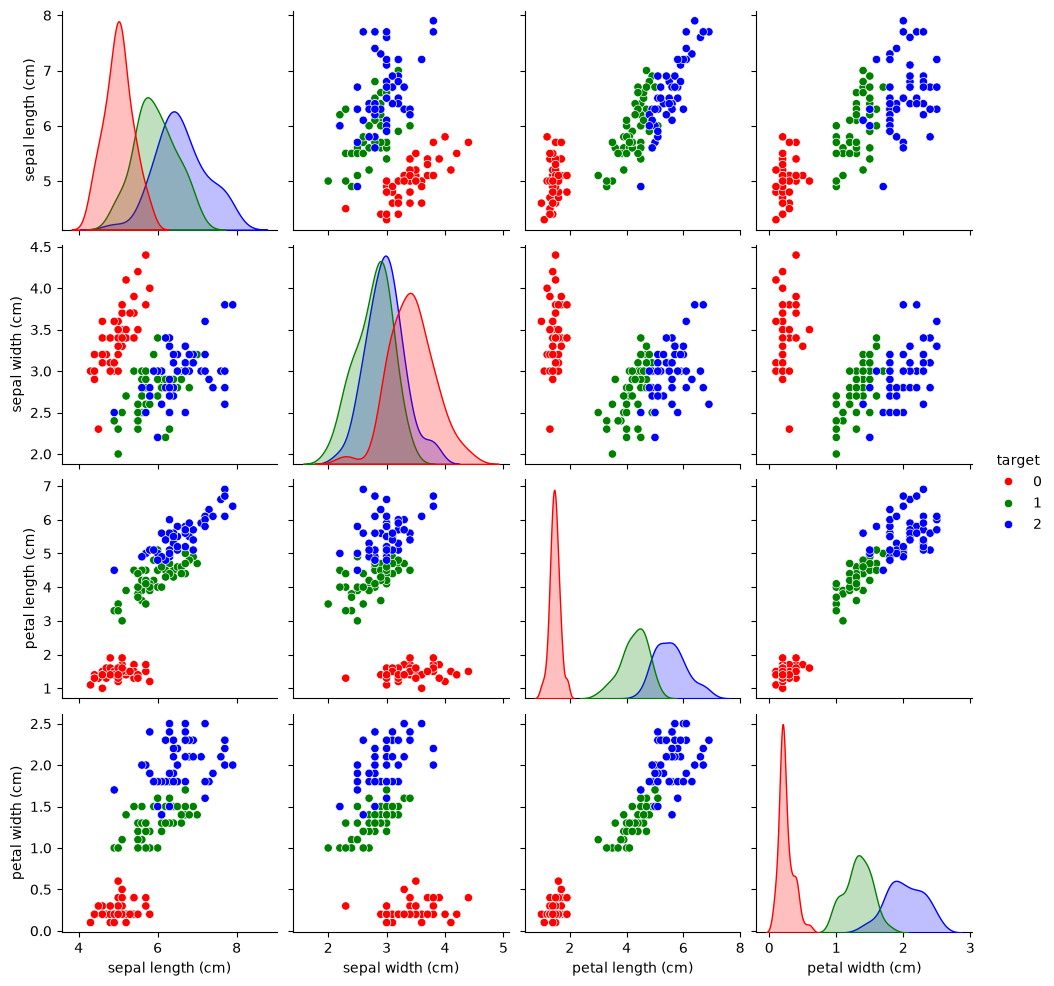

In [9]:
sns.pairplot(df, hue='target', palette=colors)
plt.show()

### П.3

In [10]:
df1 = df[df['target'].isin([0, 1])]  # setosa и versicolor
df2 = df[df['target'].isin([1, 2])]  # versicolor и virginica
print(len(df1), len(df2))

100 100


### П.4 - П.8. Датасет 1 (setosa и versicolor)

In [11]:
X1 = df1.drop('target', axis=1)
y1 = df1['target']

X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)

In [12]:
clf1 = LogisticRegression(random_state=0)
clf1.fit(X1_train, y1_train)
y1_pred = clf1.predict(X1_test)

print('Предсказание:', y1_pred)
print('Реальные значения:', y1_test.values)
print('Точность (score):', clf1.score(X1_test, y1_test))

Предсказание: [1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 1 0 1]
Реальные значения: [1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 1 0 1]
Точность (score): 1.0


### П.4 - П.8. Датасет 2 (versicolor и virginica)

In [13]:
X2 = df2.drop('target', axis=1)
y2 = df2['target']

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.3, random_state=42)

In [14]:
clf2 = LogisticRegression(random_state=0)
clf2.fit(X2_train, y2_train)
y2_pred = clf2.predict(X2_test)

print('Предсказание:', y2_pred)
print('Реальные значения:', y2_test.values)
print('Точность (score):', clf2.score(X2_test, y2_test))

Предсказание: [2 2 2 1 1 1 1 2 1 1 1 1 2 2 2 1 2 2 1 1 2 1 1 1 2 1 1 2 1 2]
Реальные значения: [2 2 2 1 1 1 1 2 1 1 1 1 2 1 2 1 2 2 1 1 2 2 1 1 2 1 1 2 1 2]
Точность (score): 0.9333333333333333


### П.9

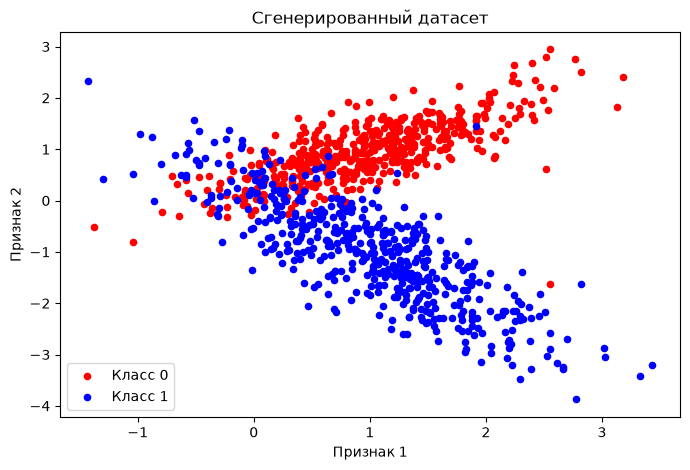

In [15]:
X, y = make_classification(n_samples=1000, n_features=2, n_redundant=0, n_informative=2,
                           random_state=1, n_clusters_per_class=1)

plt.figure(figsize=(8, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color='red', s=20, label='Класс 0')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='blue', s=20, label='Класс 1')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.title('Сгенерированный датасет')
plt.legend()
plt.show()

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

clf = LogisticRegression(random_state=0)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print('Точность (score):', clf.score(X_test, y_test))

Точность (score): 0.9366666666666666
